# Toward stochastic calculus: Brownian motion

In observing motion, we see an object that is initially over *there* move to a new spot over *here*; its *displacement*, or net change in position, is a simple quantity that one could read off a physical measuring device. The displacement does not involve or refer to anything else besides the object itself (and also the observer, who's doing the measuring). But the *motion* of the object is a composite concept, including considerations not only of the object, but also the ticking clock. As the object changes its position, so too does the present instant of time, changing its "position" as it moves from the initial instant of observation to the final instant. By comparing these two changes, we may derive measures that quantify the motion of the object; for example, its average velocity is simply the ratio of the spatial and temporal changes.

The point is this. The ticking clock, the swinging pendulum, or the regular revolution of the stars in the sky — anything that steadily marks off the passage of time may be used as a *universal, standardized* yardstick against which we may compare the change in position of *any* object.

From this vantage point, the idea at the core of stochastic calculus is truly remarkable: *Why don't we compare the movement of an object — not only against a steadily ticking clock — but also against the movement of a grain of pollen suspended in water?* As observed by the Scottish botanist Robert Brown in 1827, these grains jitter, jump, and backtrack; their movements are not regular or predictable, but rather appear to be completely random, a type of motion that is now called *Brownian motion*. If the smooth and steady swing of a pendulum provides the yardstick that leads to classical calculus, then Brown's grains of pollen provide a yardstick of a very different kind that leads to stochastic calculus. The crazy part is that all this actually *works*, leading to a mathematical theory with concrete, real-world applications (beyond tracking the movements of grains of pollen). This notebook is an introduction to this theory.

## The need for a new calculus

In this section we continue with the discussion begun in the introduction. Our purpose is to give an informal construction of the fundamental stochastic differential equation (SDE) that characterizes *diffusion processes*, whose new ingredient is a mathematical model of Brownian motion. Interpreting the solutions of the SDE will require a new type of integral belonging to stochastic calculus. In the most general setting, a careful, rigorous construction of this integral requires a good amount of measure-theoretic machinery. We leave that to the relevant textbooks; our purpose here is only to offer intuitions in the general case.

In later sections, we will specialize to the case of finite probability spaces, in which this new type of integral is a sum of random variables, Brownian motions are (approximated by) scaled random walks, and the fundamental SDE is a difference equation. All of these objects are handled by SigAlg with ease, which we will leverage to gain even more intuition.

We begin by observing a moving object. For simplicity, suppose that this object is one of the idealized "particles" that we encounter in textbooks on classical mechanics; that is, a so-called "point mass", or a featureless speck that carries mass but lacks extension. Suppose that the motion of our particle is $1$-dimensional, along some directed axis that we use to measure lengths, distances and directions. Then, over a time interval of length $\Delta t$, our particle will have undergone a net displacement of $\Delta x$ units. The ratio of these two changes, call it $\mu$, is the average velocity of the particle over that time interval. This gives the *difference* equation

$$
\Delta x = \mu \, \Delta t.
$$

We may imagine shortening the length $\Delta t$ of the time interval while keeping the initial instant of time fixed. This will, of course, also shrink the magnitude of the net displacement $\Delta x$, and the average velocity $\mu$ will (in general) change as well. Under the idealized conditions in which it is appropriate to apply classical calculus, taken "to the limit", the elapsed time $\Delta t$ transforms into its infinitesimal cousin $dt$, $\Delta x$ becomes $dx$, and the equation above is preserved, yielding the *differential* equation

$$
dx = \mu(t) \, dt, \tag{1}
$$

where $\mu(t)$ is now the "instantaneous velocity" of the particle at the initial instant of time $t$.

To obtain the position of the particle $x(t)$ at time $t$, given its position $a = x(t_0)$ at some earlier time $t_0$ and all velocities $\mu(s)$ for $t_0 \leq s \leq t$, we integrate the differential equation:

$$
x(t) = a + \int_{t_0}^t \mu(s) \, ds.
$$

This completes the description of the motion of a *classical particle* via classical calculus. In what follows, it will be useful to refer to this particle as a *deterministic* one, in the sense that its position is entirely determined at all future times $t\geq t_0$ from the velocity function $v(t)$ and its initial position. This deterministic particle contrasts with a *stochastic particle*, whose infinitesimal dynamics are modeled on the classical differential equation above, but with the addition of a new term:

$$
dx = \mu(t) \, dt + \sigma(t) \, dw. \tag{2}
$$

The first term on the right is called the *drift term* — it is carried along from the classical setting, and its role in the dynamics of the stochastic particle is no mystery. In the second term, the value $w$ is the position of a *Brownian particle*: One with no drift, whose motion is entirely random, and whose mean squared displacement over any time interval equals the length of that interval. This latter particle is the idealized, mathematical avatar of one of Brown's grains of pollen. The coefficient $\sigma(t)$ is a nonnegative function of time that scales the randomness contributed by the Brownian particle. This new differential equation is an example of a *stochastic differential equation* (*SDE*).

And here we link up with the discussion in the introduction: If in the classical differential equation ($1$) we are quantifying the movement of a particle by comparing its change in position $dx$ against $dt$, which is the regular and predictable (infinitesimal) time between two ticks of a clock, then in the new differential equation ($2$) we are also comparing $dx$ against $dw$, which is the entirely random change in position of a Brownian particle.

Drawing inspiration from the classical case, we might then imagine that the position of the stochastic particle is obtained by integration:

$$
x(t) = a + \int_{t_0}^t \mu(s) \, ds + \int_{t_0}^t \sigma(s) \, dw. \tag{3}
$$

The first integral on the right may be interpreted as a classical Riemann integral — there is no issue there. The second integral on the right might be interpreted as a Riemann-Stieltjes integral, which, provided that $w$ is continuously differentiable, gives us

$$
\int_{t_0}^t \sigma(s) \, dw = \int_{t_0}^t \sigma(s) w'(s) \, ds, \tag{4}
$$

where the integral on the right is a Riemann integral.

But there's a problem. We mentioned that the mean squared displacement of the Brownian particle over a time interval is the length of that interval. Pretending for a moment that the Brownian motion is deterministic and not random, so that we may dispense with mean values, this would imply that

$$
(\Delta w)^2 = \Delta t. \tag{5}
$$

But the derivative of $w$ that appears in ($4$) is the limit of the ratio $\Delta w / \Delta t$ as $\Delta t \to 0$. So, to the degree that these heuristic reasonings may be trusted, we conclude that the derivative *does not exist* precisely because the Brownian particle has infinite instantaneous velocity. This further implies that the differential $dw$ appearing in ($2$) is a fantasy, at least in the classical sense. So, we seem to be in a jam.

In textbooks that focus more on the applications of stochastic calculus than its theoretical foundations, the SDE ($2$) is left simply as informal notational shorthand that stands for ($3$), and the texts instead focus their energy on making sense of the mysterious $dw$-integral. It turns out that the standard interpretation of this integral is as an *Itô integral*. In the finite setting, we will see how the mysterious relation ($5$), which seems to be one of the reasons that stochastic calculus is so different from the classical kind, is unavoidably forced on us by simple physical constraints, and we will see the discrete version of the fundamental SDE ($3$) emerge naturally.

## Stochastic processes and IID processes

We begin working our way toward discrete approximations to Brownian motions, the main ingredient in the fundamental SDE and Itô integral mentioned in the previous section. This will require us to have at hand three types of stochastic processes: Independent and identically distributed processes, random walks, and scaled random walks. This section contains the definition of the first type, along with the definition of a general stochastic process that we adopt for use in SigAlg.

Let $(\Omega, \mathcal{F}, P)$ be a *finite* probability space. A *stochastic process* (or simply, a *process*) is a collection $\{X_t\}_{t\in T}$ of random variables on the probability space where $T\subset \mathbb{R}$ is a finite index set. The set $T$ is often referred to as *time*, and we often write $X$ to refer to the stochastic process.

By holding a sample point $\omega\in \Omega$ fixed and letting $t$ vary over the index set $T$, we obtain a real-valued function

$$
X(\omega):T \to \mathbb{R}, \quad t\mapsto X_t(\omega),
$$

which is called a *trajectory* (or *sample path*) of the stochastic process. Thus, a stochastic process can also be thought of as a collection of trajectories, indexed by the sample space $\Omega$.

Perhaps the simplest example of a stochastic process is an *independent and identically distributed* (*IID*) process, where each random variable $X_t$ is independent from all other random variables $X_s$ for $s \neq t$, and all random variables $X_t$ have the same distribution. A simple example of an IID process is a sequence of Bernoulli random variables indexed by a finite set $T = \{1,2,\ldots,t_1\}$, which can be used to model a sequence of $t_1$ coin flips where $X_t = 1$ represents a head and $X_t = 0$ a tail on the $t$-th flip. Such a process can be implemented in SigAlg through its interface with SciPy, as follows.

In [180]:
import sigalg as sa
from scipy.stats import bernoulli

T = sa.Time.discrete(start=1, stop=3)
X = sa.IIDProcess.generate(
    distribution=bernoulli(p=0.7),
    support=[0, 1],
    mode="enum",
    index=T,
)
print(X)

IID process 'X':
t      1  2  3
omega         
0      0  0  0
1      0  0  1
2      0  1  0
3      0  1  1
4      1  0  0
5      1  0  1
6      1  1  0
7      1  1  1


The printout shows an IID process $X$ on the index set $T = \{1,2,3\}$, where each $X_t$ is a Bernoulli random variable with parameter $p=0.7$. Since each $X_t$ has only two possible outcomes, the entire process has $2^3 = 8$ possible trajectories, all being listed in the printout.

Each trajectory $X(\omega)$ of the process has a probability, which may be computed — using independence — as the product of the probabilities of each individual random variable along the trajectory:

$$
P(X(\omega)) = \prod_{t=0}^2 P(X_t = X_t(\omega)).
$$

For example, for the trajectory corresponding to $3 \in \Omega$ (see the row indexed with `3` in the printout above) we have

$$
P(X(3)) = P(X_0 = 0) P(X_1 = 1) P(X_2 = 1) = 0.3 \cdot 0.7^2 = 0.147.
$$

The probabilities of each trajectory can be accessed via the `measure` attribute of the process:

In [181]:
print(X.measure)

Probability measure 'P':
           P
omega       
0      0.027
1      0.063
2      0.063
3      0.147
4      0.063
5      0.147
6      0.147
7      0.343


The parameter `mode="enum"` passed into the constructor tells SigAlg to exhaustively enumerate all trajectories of the given length. Longer trajectories can be generated by increasing the length of the `Time` instance, though care must be taken since the number of possible trajectories grows exponentially with the length of the process. For long trajectories, it is often more practical to work with samples of trajectories. In the next code block, we simulate a single trajectory of length $100$ from the same IID Bernoulli process above. To do this, we use that SigAlg exposes (some of) the parameters used for generating trajectories as settable properties — this allows us to generate and then regenerate trajectories of a `StochasticProcess` object without having to instantiate a new object each time.

In [182]:
# Define a longer time index
T = sa.Time.discrete(start=1, stop=100)

# Reset the generation parameters of the process
X.time = T
X.n_trajectories = 1
X.random_state = 42

# Change the generation mode to 'sim', for simulation, and regenerate the trajectories
X.mode = "sim"
X.regenerate()
print(X)

IID process 'X':
t      1    2    3    4    5    6    7    8    9    10   ...  91   92   93   \
omega                                                    ...                  
0        0    1    0    1    1    0    0    0    1    1  ...    1    1    1   

t      94   95   96   97   98   99   100  
omega                                     
0        1    1    1    1    1    1    0  

[1 rows x 100 columns]


Instances of `StochasticProcess` have the `plot_trajectories` method, which interfaces with Matplotlib. We use this method to plot the single trajectory generated above.

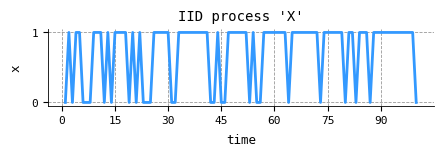

In [183]:
import matplotlib.pyplot as plt

plt.style.use("/Users/johnmyers/dev/site/aux-files/custom-theme-white.mplstyle")

# Define color palette for plots
yellow = "#FFC300"
blue = "#3399FF"
purple = "#AA77CC"

fig, ax = plt.subplots(figsize=(4.98, 1))
X.plot_trajectories(ax=ax, y_label="x", colors=[blue])
fig.savefig("bernoulli-trajectories.pdf", bbox_inches="tight")
plt.show()

A trajetory of an IID Bernoulli process is just a sequence of $0$'s and $1$'s, but Matplotlib connects them with lines for visual clarity.

## Random walks

The underlying physical explanation of Brownian motion is that a grain of pollen, when suspended in water, is experiencing near constant impacts from water molecules. In a given time interval, there may be more molecules colliding with one side of the grain than another, which results in uneven forces that are responsible for the visible jumps that characterize Brownian motion. The type of stochastic process described in this section may be conceptualized as an extremely idealized model of Brownian motion (with drift) in which the pollen grain experiences exactly one impact per unit of time.

Let $n$ be a positive integer, $a$ a real number, and $p$ a real number in the interval $[0,1]$. A *random walk* of length $n$, beginning at $a$, is a stochastic process $X$ indexed by $T = \{0,1,\ldots,n\}$ with the following properties:

1. The variable $X_0$ is deterministic, equal to $a$ for all $\omega\in \Omega$. It is called the *initial state* of the random walk.
2. The (*forward*) *increments*
    $$
    \Delta X_t \stackrel{\text{def}}{=} X_{t+1} - X_{t}, \quad t = 0,1,\ldots,n-1,
    $$
    are IID random variables.
3. Each increment $\Delta X_t$ takes either the value $1$ or $-1$, the former with probability $p$ and the latter with probability $q=1-p$.

If $p\neq 0.5$, the process $X$ is called a random walk *with drift*; otherwise, it is called a *symmetric* random walk. The "drift" terminology will be explained below when we plot trajectories of random walks.

Now, in the description of abstract (i.e., mathematical) Brownian motion, we speak of particles experiencing impacts from other particles, not grains of pollen and water molecules. So, we suppose that a particle is restricted to move along the $x$-axis, where $X_t$ denotes its position at time $t$, and that it begins at $X_0=a$. Suppose that the $x$-axis is oriented vertically, with the positive direction pointing upward, so that we speak of *upward* and *downward* movements. At each instant of time $t\in \{0,1,\ldots,n-1\}$ the particle experiences an impact from another particle which will shoot it upward by one unit with probability $p$, or downward one unit with probability $q$. In this very simple sense, a random walk models a Brownian motion (with drift).

Let's implement a random walk in SigAlg. We may use the built-in `RandomWalk` class, but it is instructive at first to build a random walk from scratch using the above recipe. To do this, note that each $X_t$ is the cumulative sum of the increments up to time $t$:

$$
X_t = X_0 + \sum_{s=0}^{t-1} \Delta X_s.
$$

For each $t$, we have

$$
\Delta X_t = 2B_t -1,
$$

where $B_t$ is a Bernoulli random variable with parameter $p$. Using these observations, we may build a random walk process as follows.

In [184]:
# Set the parameters of the random walk
n = 10
a = 2
p = 0.7
T = sa.Time.discrete(start=1, stop=n)

# Construct the increment process
B = sa.IIDProcess.generate(
    distribution=bernoulli(p),
    support=[0, 1],
    mode="sim",
    n_trajectories=1,
    index=T,
    name="B",
    random_state=42,
)
Delta_X = 2 * B - 1

# Add the initial state
Delta_X = Delta_X.insert_rv(time=0, state=a)

# Construct the random walk process by cumulative summation
X = Delta_X.cumsum(name="X")

# Print the simulated trajectories
print(X)

Stochastic process 'X':
t      0   1   2   3   4   5   6   7   8   9   10
omega                                            
0       2   1   2   1   2   3   2   1   0   1   2


(The reader will notice that we actually built the random walk $X$ using the *backward* increments $\Delta X_t = X_t - X_{t-1}$ (for $t\in \{1,2,\ldots,n\}$), and then manually inserted the initial state at time $t=0$. This was done in order to avoid awkwardly having to shift time indices if we had used the proper forward increments. The reader need not worry too much about this point, because in practice they will use the built-in class `RandomWalk`, which takes care of all this internally.)

We now plot the random walk.

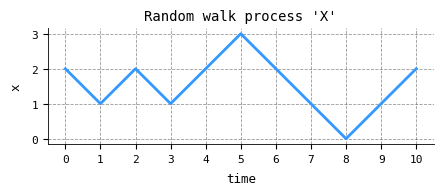

In [185]:
fig, ax = plt.subplots(figsize=(4.98, 1.5))
X.plot_trajectories(ax=ax, y_label="x", colors=[blue], title="Random walk process 'X'")
fig.savefig("rw-trajectories.pdf", bbox_inches="tight")
plt.show()

In this trajectory, the particle is initially impacted at time $t=0$ in such a way to knock it downward one unit (i.e., from $x=2$ to $x=1$); then, at time $t=1$, the particle experiences an impact that moves upward one unit (from $x=1$ back to $x=2$); and so forth.

Longer and more trajectories reveal the "drift" that we mentioned above. To make these trajectories, for convenience we turn to the `RandomWalk` class, which internally implements the same construction that we carried through by hand. The following code simulates $10$ trajectories of length $100$ from a random walk with $p=0.7$ and then plots them.

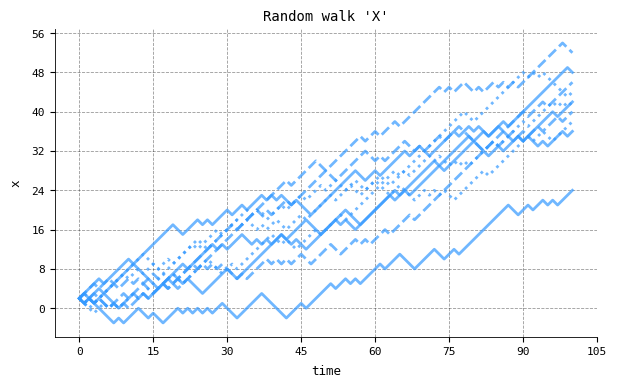

In [186]:
T = sa.Time.discrete(length=100)
X = sa.RandomWalk.generate(
    p=p,
    initial_state=a,
    mode="sim",
    n_trajectories=10,
    index=T,
    random_state=42,
)

_, ax = plt.subplots(figsize=(7, 4))
X.plot_trajectories(ax=ax, y_label="x", plot_kwargs={"alpha": 0.7}, colors=["#3399FF"])
plt.show()

While the trajectories are random, it is evident that they have a long-run inclination to drift upward. This probabilistic tendency may be seen also by computing the expected values of the increments:

$$
E(\Delta X_t) = p-q = 0.7-0.3 = 0.4 > 0.
$$

If $q$ had been greater than $p$, then we would have seen a long-run drift downward, while if $p=q$ we would obtain a symmetric random walk whose trajectories tend to move horizontally.


## The first appearence of the stochastic integral; applications to finance

Return, for a moment, to our method for generating the random walk from its increments: The equation was

$$
X_t = X_0 + \sum_{s=0}^{t-1} \Delta X_s,
$$

for all $t=0,1,\ldots,n-1$. Note the formal similarity between this equation and the equation

$$
f(x) = f(a) + \int_a^x df
$$

for a real-valued function $f$, where $x$ is any number inside a closed interval $[a,b]$ on which $f$ is defined. The integral on the right is the classical Riemann-Stieltjes integral with $f$ playing the role of the integrator and the constant function $x\mapsto 1$ the integrand. While the similarity is not an exact identity — for example, the first equation relates functions defined on the sample space $\Omega$, while the second equation relates real numbers — it does seem to suggest that the sum in the first equation resembles an integral. And, in fact, this sum is a simple case of a discrete Itô integral, to which we now turn.

The general definition is defined as follows. Let $Y$ and $Z$ be two stochastic processes, both with finite index set $T = \{t_0,t_1,\ldots,t_n\} \subset \mathbb{R}$. Then the *discrete Itô integral* of $Y$ with respect to $Z$, denote $I(Y,Z)$, is the $T$-indexed stochastic process defined by

$$
I(Y,Z)_{t_k} = \begin{cases}
\sum_{j=0}^{k-1} Y_{t_j}(Z_{t_{j+1}} - Z_{t_j}) & : 0 < k \leq n, \\
0 & : k=0.
\end{cases}
$$

Very often, we use integral notation and write

$$
\int_{t_0}^{t} Y_s \, dZ_s \stackrel{\text{def}}{=} I(Y,Z)_{t},
$$

for each $t\in T$. The random variable $Y$ is called the *integrand*, while $Z$ is called the *integrator*.

We should caution that — according to many textbook sources — our definition of the Itô integral is incomplete. For we often suppose that $Y$ is *adapted* to the *natural filtration* induced by $Z$, which means that, for each $k=0,1,\ldots,n$, the random variable $Y_{t_k}$ is measurable with respect to the $\sigma$-algebra generated by the random variables $Z_{t_0},\ldots,Z_{t_k}$. The intuitive meaning of this requirement will be explained in a later tutorial.

Returning to our random walk above, we see that

$$
X_t = X_0  + \int_0^t dX_s.
$$

The integrand in the integral is the constant random variable $\omega \to 1$, and $X$ is the integrator. We may test this equality using the last random walk programmed into SigAlg in the previous section, along with the `ito_integral` method. (Remember that $X_0 = a$.)

In [187]:
ito = sa.ProcessTransforms.ito_integral

X == a + ito(integrator=X)

True

What about Itô integrals in which the integrand is *not* a constant function?

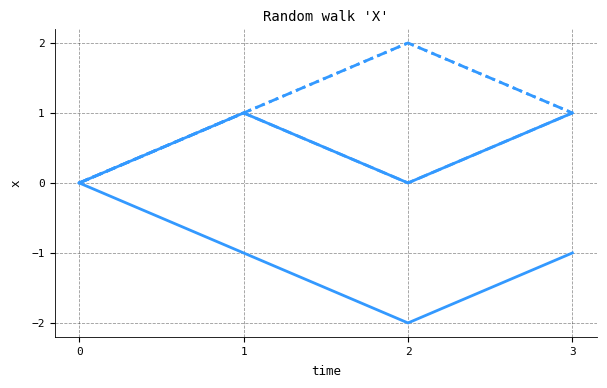

In [188]:
p = 0.5
a = 0

T = sa.Time.discrete(start=0, stop=3)
X = sa.RandomWalk.generate(
    p=p,
    initial_state=a,
    mode="sim",
    n_trajectories=5,
    index=T,
    random_state=42,
)

_, ax = plt.subplots(figsize=(7, 4))
X.plot_trajectories(ax=ax, y_label="x", colors=["#3399FF"])
plt.show()

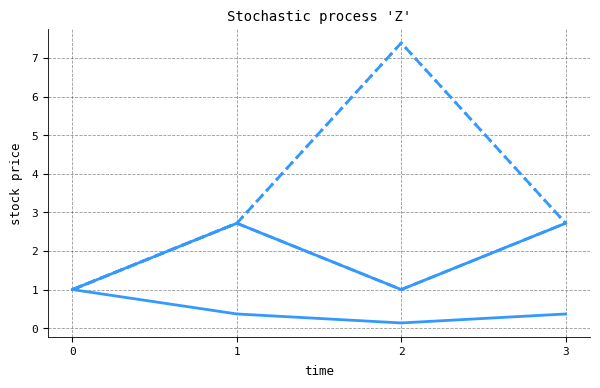

In [189]:
import numpy as np

Z = np.exp(X).with_name("Z")

_, ax = plt.subplots(figsize=(7, 4))
Z.plot_trajectories(ax=ax, y_label="stock price", colors=["#3399FF"])
plt.show()

In [190]:
def f0(Z: sa.StochasticProcess) -> sa.RandomVariable:
    return sa.RandomVariable.from_constant(*Z.prob_space, constant=1)


def f1(Z: sa.StochasticProcess) -> sa.RandomVariable:
    return 2 * (Z[1] >= Z[0])


def f2(Z: sa.StochasticProcess) -> sa.RandomVariable:
    return 2 * (Z[2] >= Z[1])



## Scaled random walks

The random walks in the previous section model a simplified version of Brownian motion (with drift) in which the particle experiences a single impact per unit of time, propelling it a distance of one unit either upward or downward. This means that, over a time interval of length $n$, the particle would experience $n$ impacts, displacing it a maximum distance of $n$ units away from its initial position. But in a *true* Brownian motion, these impacts are nearly constant, and in this section we attempt to model the position of a particle undergoing this type of motion. To do this, we decouple the length of the time interval and the number of impacts, and we let the latter number go to $\infty$ while holding the time interval fixed. However, if each impact propels the particle one unit, it is conceivable that the trajectory of the particle might be unbounded. So, to balance the number of particle impacts going to $\infty$, we must correspondingly shrink the distance that each impact propels the particle.

In more detail, suppose that the initial position of our particle is represented by a real number $x=a$ on the $x$-axis (laid out vertically as described above, so we talk of *upward* and *downward* movements). Time begins at $t=0$, when the particle is at $x=a$, and we let a time interval of length $t_1>0$ tick off the clock. We divide the time interval $[0,t_1]$ into $n$ subintervals, each of length $\Delta t = t_1/n$. At each time $k\Delta t$ ($k=0,1,\ldots,n-1$), we suppose the particle experiences an impact from another particle that will propel it either upward or downward a distance of $h$ units, where $h$ is some positive real number. An upward movement occurs with probability $p$, while a downward movement occurs with the complementary probability $q=1-p$.

The position of the particle is modeled by a stochastic process $X_t$, indexed by $t\in T = \{0,\Delta t,2\Delta t\ldots,n\Delta t\}$, with the following properties:

1. The variable $X_0$ is deterministic, equal to $a$ for all $\omega\in \Omega$. 
2. The forward increments
    $$
    \Delta X_{k\Delta t} = X_{(k+1)\Delta t} - X_{k\Delta t}, \quad k = 0,1,\ldots,n-1,
    $$
    are IID random variables.
3. Each increment $\Delta X_{t}$ takes either the value $h$ or $-h$, the former with probability $p$ and the latter with probability $q=1-p$.

The ultimate goal, then, is to understand what happens as $n\to\infty$. This will force the temporal step size $\Delta t$ to go to $0$, and as we mentioned above, in order to avoid having the particle fly off to $\pm \infty$, we will also have to arrange so that the spatial step size $h$ goes to $0$ as well. In doing so, the reader will see the discrete version of the fundamental SDE (2) emerge quite naturally, along with the mysterious relation (5).

We begin by defining a $T$-indexed stochastic process $Y_t$ via the difference equations

$$
\Delta X_{k\Delta t} = h(p-q) + \Delta Y_{k\Delta t}, \quad k=0,1,\ldots,n-1,
$$

along with the initial condition $Y_0=0$. Notice that the increments $\Delta Y_{t}$ are independent and identically distributed, and that their expectations and variances are given by

$$
E(\Delta Y_{k\Delta t}) = 0, \quad V(\Delta Y_{k\Delta t}) = 4h^2pq.
$$

The difference equation may be solved by summing both sides from $k=0$ to $n-1$, yielding

$$
X_{t_1} = a+ \frac{t_1 h(p-q)}{\Delta t} + \sum_{k=0}^{n-1} \Delta Y_{k\Delta t}.
$$

We then have

$$
E(X_{t_1}) = a + \frac{t_1 h(p - q)}{\Delta t}, \quad V(X_{t_1}) = \frac{4t_1 h^2pq}{\Delta t}.
$$

These two expressions demonstrate the dangers involved in letting the temporal and spatial step sizes $\Delta t$ and $h$ to go $0$ indiscriminately, for if we do not do so in a controlled manner, these expectations and variances will either diverge to $\pm \infty$ or vanish. To ensure that the variance remains under control, we require

$$
\Delta t \propto h^2, \tag{6}
$$

so that there is a positive constant $\sigma^2$ such that $\Delta t = h^2/\sigma^2$. This constant, which has units of squared length per time, is called a *diffusion coefficient*. The proportionality relation ($6$) is the embryonic form of the relation ($5$) mentioned above, which is responsible for much of the difference between stochastic and classical calculus.

However, the existence of the diffusion coefficient alone is not sufficient to keep the dynamics of the particle under control as the temporal and spatial step sizes go to $0$. Indeed, supposing that the probabilities $p$ and $q$ are *fixed* and not both equal to $1/2$, the expectation of $X_{t_1}$ will blow up to $\pm \infty$ as $h\to 0$. To avoid this, we require that

$$
p-q \propto h,
$$

so that there is a constant $\mu$ for which $p-q = \mu h/\sigma^2$. Since $p$ and $q$ are both probabilties, and hence $|p-q| \leq 1$, the existence of this constant requires $|\mu| \leq \sigma^2/ h$, a bound which grows larger the smaller $h$ is, so in the limit as $h\to 0$ any choice of $\mu$ is possible and $\mu$ and $\sigma^2$ are completely independent. The constant $\mu$, which has units of length per time, is called a *drift coefficient*.

With chosen diffusion and drift coefficients, one then computes

$$
E(X_{t_1}) = a + \mu t_1, \quad \lim_{h\to 0} V(X_{t_1}) = \sigma^2t_1.
$$

Using SigAlg, we generate and plot sample trajectories of these scaled random walks over the time interval $[0,10]$, beginning at $a=0$, and for various choices of (spatial) step size $h$, diffusion coefficient $\sigma^2$, and drift coefficient $\mu$.

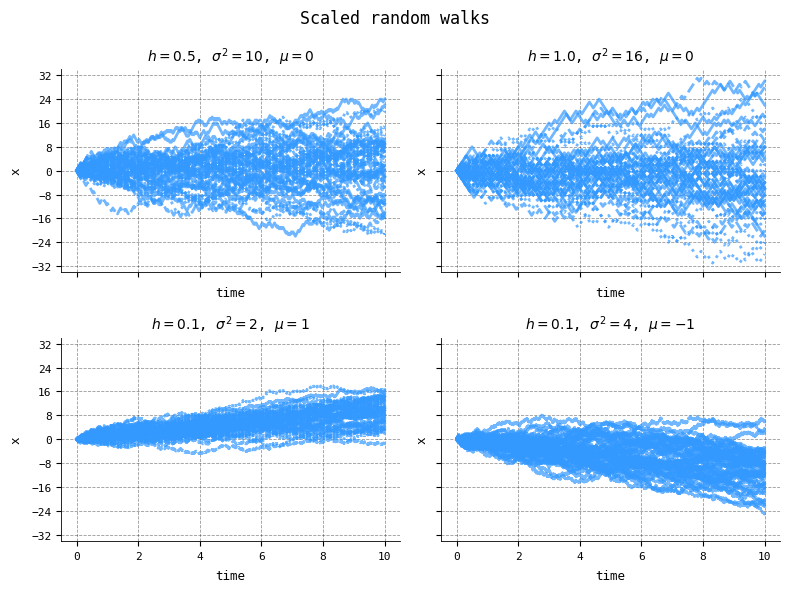

In [191]:
def gen_random_walk(h, sig_2, mu, t_1, n_trajectories, random_state=None, name="X"):  # noqa: D103
    if abs(mu) > sig_2 / h:
        raise ValueError(
            "The mu value is outside the allowed range |mu| <= sigma^2 / h."
        )

    tau = h**2 / sig_2  # temporal step size
    p = (mu * h) / (2 * sig_2) + (1 / 2)  # probability of up move

    T = sa.Time.continuous(start=tau, stop=t_1, dt=tau)

    B = sa.IIDProcess.generate(
        distribution=bernoulli(p),
        mode="sim",
        n_trajectories=n_trajectories,
        index=T,
        name="B",
        random_state=random_state,
    )
    Delta_X = h * (2 * B - 1)
    Delta_X = Delta_X.insert_rv(time=0, state=0)
    return Delta_X.cumsum(name=name)


params = [
    {"h": 0.5, "sig_2": 10, "mu": 0, "t_1": 10},
    {"h": 1.0, "sig_2": 16, "mu": 0, "t_1": 10},
    {"h": 0.1, "sig_2": 2, "mu": 1, "t_1": 10},
    {"h": 0.1, "sig_2": 4, "mu": -1, "t_1": 10},
]

fig, axs = plt.subplots(2, 2, figsize=(8, 6), sharex=True, sharey=True)

for i, (param, ax) in enumerate(zip(params, axs.flat), 1):
    X = gen_random_walk(**param, n_trajectories=50, random_state=42, name=f"X_{i}")
    X.plot_trajectories(
        ax=ax,
        y_label="x",
        colors=["#3399FF"],
        plot_kwargs={"alpha": 0.7},
        title=rf"$h={param['h']}$, $\sigma^2={param['sig_2']}$, $\mu={param['mu']}$",
    )

fig.suptitle("Scaled random walks")
plt.tight_layout()
plt.show()

The plots reveal that the drift coefficient has the expected effect: Positive coefficients yield trajectories that tend to drift upward over the long run, while trajectories with negative coefficients tend to drift downward. Larger values of the diffusion coefficient produce trajectories that are are more erratic or "noisier".

## Emergence of Brownian motion

We retain the setup and notation from the previous section, and we return to the fundamental difference equation

$$
\Delta X_{t} = h(p-q) + \Delta Y_{t}.
$$

With a chosen drift coefficient $\mu$, the deterministic part on the right-hand side may be rewritten so that

$$
\Delta X_{t} = \mu \Delta t + \Delta Y_{t}.
$$

If we define a stochastic process $W_t$ by setting $W_t=Y_{t} / \sigma$, where $\sigma$ is the positive square root of the diffusion coefficient $\sigma^2$, then we have

$$
\Delta X_{t} = \mu \Delta t + \sigma \Delta W_{t}.
$$

*This is the discrete version of the fundamental SDE (2)*. The same computations from the previous section also lead us to the equalities

$$
E(W_{t_1}) = 0, \quad \lim_{h\to 0} V(W_{t_1}) = t_1.
$$

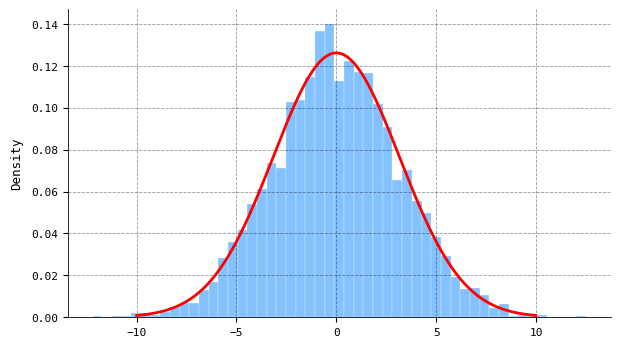

In [192]:
import numpy as np
import seaborn as sns
from scipy.stats import norm

h = 0.1
sig_2 = 4
sig = 2
mu = 1
t_1 = 10

X = gen_random_walk(h, sig_2, mu, t_1, n_trajectories=5_000, random_state=42)
W_t_1 = X[t_1] / sig - mu * t_1 / sig
N = norm(loc=0, scale=t_1**0.5)

_, ax = plt.subplots(figsize=(7, 4))
x = np.linspace(-10, 10, 500)
ax.plot(x, N.pdf(x), color="red", linewidth=2, zorder=3)
sns.histplot(
    data=W_t_1, stat="density", ax=ax, color="#3399FF", edgecolor="white", alpha=0.6
)
plt.show()